# Приотизация обращений

### Установка зависимостей

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from catboost import CatBoostClassifier

# Пути к данным.
ROOT = Path(".")
DATA_DIR = ROOT / "data"

TARGET = "target"

# Эти колонки не используем как признаки модели.
ID_COLUMNS = {"lead_id", "user_id"}
TIME_COLUMNS = {"assignment_ts", "assignment_date"}
NON_FEATURE_COLUMNS = ID_COLUMNS | TIME_COLUMNS | {TARGET}
CATEGORICAL_COLUMNS = ["lead_source", "call_center", "region", "car_segment", "lead_channel", "user_tenure_bucket", "price_bucket"]
WINDOWS = ["1d", "3d", "7d", "14d", "30d", "90d"]
ACTIVITY_COUNTERS = [
    "item_views", "item_favorites", "detail_expands", "photo_swipes",
    "seller_page_views", "search_views", "query_refinements",
    "similar_item_clicks", "saved_search_matches", "user_contacts",
    "chat_opens", "call_clicks", "active_days_auto",
]
EVENT_TYPES = ["item_view", "search", "favorite", "chat_open", "call_click"]
RARE_CTX = ["c03", "c05", "c07"]
RARE_SLOTS = [1, 24, 25]

RANDOM_STATE = 42

### Загрузка данных

Загружаем обучающую выборку, тестовую выборку и события.

In [2]:
train = pd.read_csv(DATA_DIR / "train.csv", parse_dates=["assignment_ts"])
test = pd.read_csv(DATA_DIR / "test.csv", parse_dates=["assignment_ts"])
events = pd.read_csv(DATA_DIR / "events.csv", parse_dates=["event_ts"])

print("train:", train.shape)
print("test:", test.shape)
print("events:", events.shape)
print("target mean:", train[TARGET].mean())

train: (13694, 119)
test: (4306, 118)
events: (254705, 7)
target mean: 0.20746312253541696


In [3]:
train.head(5)

,lead_id,user_id,assignment_ts,assignment_date,lead_source,call_center,region,car_segment,lead_channel,user_tenure_bucket,...,leadgen_prev_positive_14d,leadgen_prev_positive_30d,leadgen_prev_positive_90d,active_days_auto_1d,active_days_auto_3d,active_days_auto_7d,active_days_auto_14d,active_days_auto_30d,active_days_auto_90d,target
0,lead_f57db09ab39ae3e7,user_0000001,2026-04-22 11:56:00,2026-04-22,CRM,external,west,budget,retargeting,warm,...,0.0,0.0,0.0,0.0,0.0,0.0,4.0,9.0,26.0,0
1,lead_a6184b8a8165a27b,user_0000002,2026-04-07 14:49:00,2026-04-07,CRM,voxys,north,standard,partner,warm,...,0.0,NaN,1.0,0.0,0.0,0.0,NaN,4.0,5.0,0
2,lead_229c2a117dbac203,user_0000003,2026-04-12 17:01:00,2026-04-12,Perf,external,north,budget,retargeting,new,...,0.0,0.0,NaN,2.0,4.0,1.0,10.0,12.0,52.0,0
3,lead_16b19e58042ef905,user_0000005,2026-04-13 21:39:00,2026-04-13,Model,voxys,east,premium,partner,warm,...,0.0,1.0,0.0,0.0,1.0,0.0,3.0,2.0,NaN,1
4,lead_734c227324978a36,user_0000006,2026-04-12 18:01:00,2026-04-12,CRM,voxys,central,budget,retargeting,warm,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0,9.0,0


In [4]:
test.head(5)

,lead_id,user_id,assignment_ts,assignment_date,lead_source,call_center,region,car_segment,lead_channel,user_tenure_bucket,...,leadgen_prev_positive_7d,leadgen_prev_positive_14d,leadgen_prev_positive_30d,leadgen_prev_positive_90d,active_days_auto_1d,active_days_auto_3d,active_days_auto_7d,active_days_auto_14d,active_days_auto_30d,active_days_auto_90d
0,lead_97e409eb8f8c8246,user_0000000,2026-04-27 13:09:00,2026-04-27,CRM,voxys,north,commercial,retargeting,new,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,2.0,9.0,34.0
1,lead_55310edb4489f9e9,user_0000004,2026-04-24 14:48:00,2026-04-24,Model,voxys,east,standard,retargeting,warm,...,0.0,0.0,1.0,0.0,0.0,0.0,2.0,1.0,6.0,12.0
2,lead_e7f653a2c6a7eee8,user_0000019,2026-04-27 16:00:00,2026-04-27,Model,voxys,west,commercial,app,new,...,0.0,0.0,1.0,0.0,1.0,3.0,4.0,3.0,2.0,21.0
3,lead_22f8e1cfc487ac20,user_0000021,2026-04-27 11:56:00,2026-04-27,Model,external,north,commercial,web,loyal,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,3.0,11.0
4,lead_48b638b839abfac3,user_0000023,2026-04-26 10:13:00,2026-04-26,CRM,voxys,east,standard,app,warm,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,2.0,4.0,9.0


In [5]:
events.head(5)

,lead_id,user_id,event_ts,event_type,item_price_log,src_slot,ctx_seq
0,lead_00025e9610a0d90d,user_0016636,2026-03-27 06:41:00,chat_open,13.303438,19.0,c02
1,lead_00025e9610a0d90d,user_0016636,2026-03-31 09:10:00,item_view,13.322707,6.0,c06
2,lead_00025e9610a0d90d,user_0016636,2026-04-02 22:04:00,item_view,13.395721,10.0,c06
3,lead_00025e9610a0d90d,user_0016636,2026-04-04 09:19:00,search,13.395955,10.0,c04
4,lead_00025e9610a0d90d,user_0016636,2026-04-07 12:36:00,item_view,13.472769,2.0,c02


Создадим список численных признаков для дальнейшей работы

In [6]:
numeric_features = [c for c in train.columns 
                    if c not in NON_FEATURE_COLUMNS
                    and c not in CATEGORICAL_COLUMNS]
feature_columns = [c for c in train.columns if c not in NON_FEATURE_COLUMNS]

## EDA

### 1. Временная структура 

Так как каждая строка в данных это обращение в конкретный день, посмотрим как периоды train и test расположены по времени, есть ли пересечения, от этого зависит способ валидации.

In [7]:
temporal_structure = pd.DataFrame({
    "min_date": [train["assignment_date"].min(), test["assignment_date"].min()],
    "max_date": [train["assignment_date"].max(), test["assignment_date"].max()],
    "n_days": [train["assignment_date"].nunique(), test["assignment_date"].nunique()],
    "n_rows": [len(train), len(test)],
}, index=["train", "test"])
print(temporal_structure)
intersection_date = set(train["assignment_date"]) & set(test["assignment_date"])
print(f"Пересекающихся дат: {len(intersection_date)}")

         min_date    max_date  n_days  n_rows
train  2026-04-07  2026-04-22      16   13694
test   2026-04-23  2026-04-27       5    4306
Пересекающихся дат: 0


**Вывод** Train и Test не пересекаются по времени, test идет после train, валидировать модель будем на последних 4 днях обучающей выборки, имитируя предсказание будущего. Random split не подходит в следствие того, что будет подглядывать в будущее.  

### 2. Баланс классов 

Daily AP усредняет Average Precision по дням, поэтому посмотрим на баланс классов по дням.

In [8]:
daily = train.groupby("assignment_date")[TARGET].agg(n_leads="size", n_pos="sum", positive_rate="mean", ).round(4)
daily

,n_leads,n_pos,positive_rate
assignment_date,,,
2026-04-07,873,195,0.2234
2026-04-08,832,174,0.2091
2026-04-09,859,177,0.2061
2026-04-10,830,183,0.2205
2026-04-11,861,175,0.2033
2026-04-12,855,174,0.2035
2026-04-13,791,163,0.2061
2026-04-14,842,166,0.1971
2026-04-15,899,179,0.1991


In [9]:
overall_rate = train[TARGET].mean()
d_pr = daily.positive_rate
print(f"Общий positive_rate: {overall_rate:.4f}")
print(f"positive_rate по дням: min={d_pr.min():.4f}, max={d_pr.max():.4f}, std={d_pr.std():.4f}")
print(f"Дней с одним классом: {((d_pr == 0) | (d_pr == 1)).sum()}")

Общий positive_rate: 0.2075
positive_rate по дням: min=0.1916, max=0.2354, std=0.0118
Дней с одним классом: 0


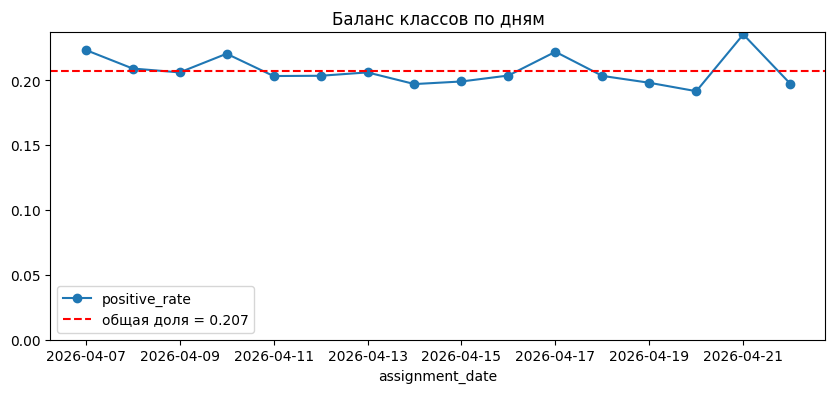

In [10]:
ax = daily["positive_rate"].plot(marker="o", figsize=(10, 4), ylim=(0, None), title="Баланс классов по дням")
ax.axhline(overall_rate, color="red", linestyle="--", label=f"общая доля = {overall_rate:.3f}")
ax.legend()
plt.show()

**Вывод:** Доля успешных лидов стабильна по дням, 0.19-0.24, mean = 0.208, std = 0.012, без трендов, дней с одним классом нет. Daily AP будет считаться без искажений от вырожденных дней и перекоса размеров. Балансировка классов не нужна: дисбаланс умеренный, метрика ранжирующая. Явных временных сдвигов нет.

### 3. Пересечение пользователей

Посмотрим, пересекаются ли пользователи, так как если один пользователь встречается и в train, и в test, его история может связать выборки (лик), и придется строить валидацию с учетом групп.

In [11]:
intersection_users = set(train["user_id"]) & set(test["user_id"])
print(f"Общих user_id между train и test: {len(intersection_users)}")
print(f"Уникальных user_id: train={train['user_id'].nunique()}, test={test['user_id'].nunique()}")

Общих user_id между train и test: 0
Уникальных user_id: train=13694, test=4306


**Вывод:** Общих user_id нет, и каждый user_id встречается только один раз. Лика через пользователя не будет, group split не нужен, а user_id будет для нас неинформативным признаком.

### 4. Согласованность train и test

Перед построением признаков проверим, что признаки в train и test устроены одинаково: совпадают признаки и типы, а в категориальных признаках test нет значений, которых не было в train, чтобы не разошлось кодирование категорий.

In [12]:
only_train = set(train.columns) - set(test.columns)
only_test = set(test.columns) - set(train.columns)
print(f"Только в train {only_train}")
print(f"Только в test {only_test}")

general_signs = [c for c in train.columns if c in test.columns]
mismatch_type = {}
for sign in general_signs:
    if train[sign].dtype != test[sign].dtype:
        mismatch_type[sign] = (str(train[sign].dtype), str(test[sign].dtype))
print(f"Несовпадения признаков: {mismatch_type or 'нет'}")

new_categories = {}
for column in CATEGORICAL_COLUMNS:
    new_in_test = set(test[column].dropna().unique()) - set(train[column].dropna().unique())
    if new_in_test:
        new_categories[column] = new_in_test
print(f"Новые категории: {new_categories or 'нет'}")

Только в train {'target'}
Только в test set()
Несовпадения признаков: нет
Новые категории: нет


**Вывод:** Схема согласована: колонки (кроме target) и типы совпадают, новых категорий в test нет. Признаки строятся одинаково, обработка ранеее не встречавшихся значений не нужна.

### 5. Пропуски 

Посмотрим на пропуски в данных, их количество, в скольки колонках они есть, совпадаем ли их количество в train и test, связан ли пропуск с целевой переменной. 

In [13]:
missing_share = train.isna().mean()
missing_share = missing_share[missing_share > 0].sort_values(ascending=False)
print(f"Колонок с пропусками: {len(missing_share)} из {train.shape[1]}")
print(f"Доля пропусков: от {missing_share.min():.3f} до {missing_share.max():.3f}, " 
      f"медиана {missing_share.median():.3f}")

missing_share_diff = (missing_share - test[missing_share.index].isna().mean()).abs().max()
print(f"Максимальное расхождение между train и test: {missing_share_diff:.3f}")

missing_mask = train[missing_share.index].isna().astype(int)
missing_target_corr = missing_mask.corrwith(train[TARGET]).abs().max()
print(f"Mаксимальная корреляция наличия пропуска с таргетом: {missing_target_corr:.3f}")

Колонок с пропусками: 97 из 119
Доля пропусков: от 0.026 до 0.052, медиана 0.030
Максимальное расхождение между train и test: 0.007
Mаксимальная корреляция наличия пропуска с таргетом: 0.028


**Вывод:** 97 колонок с пропусками, примерно по 3%, картина в train и test почти одинаковая (максимальное расхождение = 0.007), факт пропуска не связан с таргетом. Похоже, что пропуски случайны (MCAR). Для градиентного бустинга пропуски заполнять не будем: CatBoost/LightGBM сами выбирают, куда направлять пропуски на каждом сплите, это более гибко, чем фиксированная импутация, и не будет портить счетчики активности, где 0 - отсутствие активности. Импутация медианой понадобится только в логистической регрессии, которая не умеет работать с NaN.

### 6. Чистота данных
Проверим чистоту данных: нет ли физически невозможных значений, константных колонок, полностью дублирующих друг друга признаков и дубликатов строк по признакам.

In [14]:
bounds = train[numeric_features].describe().T[["min", "50%", "max"]]
n_unique = train[numeric_features].nunique()
is_duplicate = train[numeric_features].T.duplicated()
dup_by_features = train.duplicated(subset=feature_columns).sum()
negative_min = bounds[bounds["min"] < 0].index.tolist()

print(f"Признаки с отрицательным минимумом: {negative_min or 'нет'}")
print(f"Константные признаки (1 значение): {n_unique[n_unique == 1].index.tolist() or 'нет'}")
print(f"Дублирующие колонки: {train[numeric_features].columns[is_duplicate].tolist() or 'нет'}")
print(f"Строк с полным совпадением признаков (без id): {dup_by_features or 'нет'}")
print("\nГраницы числовых признаков")
print(bounds.sort_values("max", ascending=False).round(1).to_string())

Признаки с отрицательным минимумом: нет
Константные признаки (1 значение): нет
Дублирующие колонки: нет
Строк с полным совпадением признаков (без id): нет

Границы числовых признаков
                            min    50%     max
user_age_days               1.0  286.0  4088.0
item_views_90d             11.0   80.0   451.0
search_views_90d            5.0   49.0   279.0
photo_swipes_90d            3.0   41.0   223.0
seller_inventory_count      1.0   12.0   184.0
item_views_30d              0.0   27.0   159.0
search_views_30d            0.0   16.0    99.0
similar_item_clicks_90d     0.0   16.0    94.0
photo_swipes_30d            0.0   13.0    87.0
item_views_14d              0.0   13.0    77.0
query_refinements_90d       0.0   12.0    72.0
detail_expands_90d          0.0   11.0    71.0
active_days_auto_90d        0.0   11.0    68.0
item_favorites_90d          0.0    7.0    49.0
search_views_14d            0.0    8.0    45.0
user_contacts_90d           0.0    6.0    44.0
item_views_7d     

**Вывод:** Данные чистые: отрицательных значений, константных и дублирующих колонок, а также дубликатов строк по признакам не обнаружено. Максимумы и минимумы правдоподобны, аномальных значений нет.

### 7. Информативность признаков  
Чтобы понять, на что опираться при построении признаков и выборе модели, посмотрим на кардинальность категориальных признаков и наличие редких значений, насколько дублируют друг друга окна агрегации, на линейную связь с таргетом и насколько каждый категориальный признак различает исход.

In [15]:
print("Кардинальность и редкие значения категориальных признаков:")
for col in CATEGORICAL_COLUMNS:
    share = train[col].value_counts(normalize=True)
    n_rare = (share < 0.01).sum()
    print(f"{col:<20} Кол-во уникальных: {train[col].nunique()}, "
          f"min доля={share.min():.3f}, редких: {n_rare}")
    
print("\nКорреляция соседних окон (среднее по счётчикам):")
for short, long in zip(WINDOWS[:-1], WINDOWS[1:]):
    corrs = []
    for counter in ACTIVITY_COUNTERS:
        corr = train[f"{counter}_{short}"].corr(train[f"{counter}_{long}"])
        corrs.append(corr)
    print(f"{short}-{long}: {np.mean(corrs):.3f}")
    
target_corr = train[numeric_features].corrwith(train[TARGET]).abs().sort_values(ascending=False)
print(f"\nЧисловые признаки с коэф. корреляции Пирсона > 0.1:"
      f"{(target_corr > 0.1).sum()} из {len(target_corr)}")
print(target_corr.head(5).round(3).to_string())
    
print(f"\nДоля успешных лидов по значениям категории(в среднем {train[TARGET].mean():.3f}):")
for col in CATEGORICAL_COLUMNS:
    rate = train.groupby(col)[TARGET].mean()
    print(f"{col:<20} {rate.min():.3f}..{rate.max():.3f} (разброс {rate.max() - rate.min():.3f})")

Кардинальность и редкие значения категориальных признаков:
lead_source          Кол-во уникальных: 3, min доля=0.231, редких: 0
call_center          Кол-во уникальных: 2, min доля=0.424, редких: 0
region               Кол-во уникальных: 5, min доля=0.197, редких: 0
car_segment          Кол-во уникальных: 4, min доля=0.094, редких: 0
lead_channel         Кол-во уникальных: 4, min доля=0.247, редких: 0
user_tenure_bucket   Кол-во уникальных: 3, min доля=0.248, редких: 0
price_bucket         Кол-во уникальных: 3, min доля=0.179, редких: 0

Корреляция соседних окон (среднее по счётчикам):
1d-3d: 0.099
3d-7d: 0.201
7d-14d: 0.326
14d-30d: 0.464
30d-90d: 0.643

Числовые признаки с коэф. корреляции Пирсона > 0.1:57 из 107
search_views_90d    0.272
item_views_90d      0.265
item_views_30d      0.253
search_views_30d    0.251
item_views_14d      0.251

Доля успешных лидов по значениям категории(в среднем 0.207):
lead_source          0.148..0.265 (разброс 0.118)
call_center          0.189..0.233 

**Вывод:**  
Категориальные признаки имеют низкую кардинальность (2-5 значений), редких категорий нет. Доля успеха по значениям различается неоднородно: сильнее всего исход различает `lead_source` (0.118). Заметны `car_segment` (0.057) и `call_center` (0.044). `region` (0.011), `user_tenure_bucket` (0.003), `price_bucket` (0.005) почти не различают. Оставляем всё, бустинг сам их взвесит.

Окна агрегации. Соседние окна коррелируют тем сильнее, чем длиннее: 1d-3d = 0.099, 30d-90d = 0.643. Короткие окна несут почти независимую информацию, длинные частично дублируются - мотивирует создать ratio-признаки на длинных окнах (недавняя активность к фоновой).

Связь с таргетом. Линейный сигнал есть у многих численных признаков (57 из 107 с |corr| > 0.1), сильнее всего у окон просмотров и поиска (30-90 дней, 0.27), но распределен по многим признакам, поэтому будем смотреть на бустинг.

### 8. Дрейф train/test 

Проверяем не сместиться ли распределения признаков между train и test. Для числовых смотрим сдвиг среднего в единицах стандартного отклонения, для категориальных - расхождение долей категорий. Если дрейфа нет, модель, обученная на train, переносится на test без поправок.

In [16]:
mean_abs_diff = (train[numeric_features].mean() - test[numeric_features].mean()).abs()
numeric_shift = (mean_abs_diff / train[numeric_features].std()).sort_values(ascending=False)
print("Топ 5 сдвигов среднего (в std)")
print(numeric_shift.head(5).round(4).to_string())

categorical_shift = {}
for feature in CATEGORICAL_COLUMNS:
    share_train = train[feature].value_counts(normalize=True)
    share_test = test[feature].value_counts(normalize=True)
    categorical_shift[feature] = share_train.sub(share_test, fill_value=0).abs().max()
print("\nКатегориальные максимальное расхождение долей:")
print(pd.Series(categorical_shift).round(4).to_string())


Топ 5 сдвигов среднего (в std)
assignment_weekday          0.3733
is_weekend                  0.3047
car_age_years               0.0598
leadgen_prev_answered_1d    0.0427
user_contacts_1d            0.0371

Категориальные максимальное расхождение долей:
lead_source           0.0148
call_center           0.0087
region                0.0125
car_segment           0.0051
lead_channel          0.0107
user_tenure_bucket    0.0046
price_bucket          0.0221


**Вывод.** Категориальные признаки практически не сдвинуты (максимальное расхождение 0.022). А в числовых выделяются `assignment_weekday` (0.37 std) и `is_weekend` (0.30 std), однако это ожидаемо, так как у test и train разные наборы дней недели. Остальные числовые сдвинуты на сотые доли стандартного отклонения. Дрейфа нет: отбор стабильных признаков и adversarial validation не нужны.

### 9. Events

In [17]:
print("Размер events:", events.shape)
print("\nКолонки и типы:")
print(events.dtypes.to_string())
print("\nПервые строки:")
events.head(10)

Размер events: (254705, 7)

Колонки и типы:
lead_id                      str
user_id                      str
event_ts          datetime64[us]
event_type                   str
item_price_log           float64
src_slot                 float64
ctx_seq                      str

Первые строки:


,lead_id,user_id,event_ts,event_type,item_price_log,src_slot,ctx_seq
0,lead_00025e9610a0d90d,user_0016636,2026-03-27 06:41:00,chat_open,13.303438,19.0,c02
1,lead_00025e9610a0d90d,user_0016636,2026-03-31 09:10:00,item_view,13.322707,6.0,c06
2,lead_00025e9610a0d90d,user_0016636,2026-04-02 22:04:00,item_view,13.395721,10.0,c06
3,lead_00025e9610a0d90d,user_0016636,2026-04-04 09:19:00,search,13.395955,10.0,c04
4,lead_00025e9610a0d90d,user_0016636,2026-04-07 12:36:00,item_view,13.472769,2.0,c02
5,lead_00025e9610a0d90d,user_0016636,2026-04-08 23:15:00,item_view,13.483640,19.0,c02
6,lead_00025e9610a0d90d,user_0016636,2026-04-12 11:09:00,item_view,13.541322,2.0,c01
7,lead_00025e9610a0d90d,user_0016636,2026-04-15 08:00:00,item_view,13.354183,21.0,c01
8,lead_00025e9610a0d90d,user_0016636,2026-04-17 11:31:00,call_click,13.295903,23.0,c08
9,lead_00025e9610a0d90d,user_0016636,2026-04-18 14:49:00,search,13.359886,15.0,c04


In [18]:
print("Пропуски по колонкам:")
print(events.isna().mean().round(4).to_string())

print("\nУникальных значений:")
for col in ["event_type", "src_slot", "ctx_seq"]:
    print(f"{col}: {events[col].nunique()}")

print("\nТипы событий:")
print(events["event_type"].value_counts().to_string())

print("\nsrc_slot:")
print(events["src_slot"].value_counts().to_string())

print("\nctx_seq:")
print(events["ctx_seq"].value_counts().to_string())

Пропуски по колонкам:
lead_id           0.0
user_id           0.0
event_ts          0.0
event_type        0.0
item_price_log    0.0
src_slot          0.0
ctx_seq           0.0

Уникальных значений:
event_type: 5
src_slot: 25
ctx_seq: 8

Типы событий:
event_type
item_view     120905
search         61101
favorite       26333
chat_open      24797
call_click     21569

src_slot:
src_slot
13.0    11776
10.0    11748
6.0     11726
15.0    11725
18.0    11700
14.0    11684
16.0    11660
9.0     11632
17.0    11588
7.0     11545
5.0     11534
23.0    11529
8.0     11520
4.0     11507
11.0    11482
21.0    11468
19.0    11464
20.0    11444
12.0    11387
22.0    11345
3.0     11232
2.0     10877
24.0      671
25.0      316
1.0       145

ctx_seq:
ctx_seq
c01    60728
c02    55370
c06    50496
c04    50423
c08    35455
c05      935
c07      930
c03      368


**Вывод:** В events 254705 событий 5 признаков без пропусков. В `src_slot` резкий разрыв, 2-23 встречаются более десяти тысяч раз, а 1/24/25 меньше тысячи.  В `ctx_seq` также резкий разрыв, с01/с02/с06/с04/с08 встречаются десятки тысяч раз, а с03/с05/с07 меньше тысячи. В дальнейшем проверим эти редкие значения на связь с таргетом. 

Посмотрим на долю временного лика (долю событий после назначения). В events.csv есть `lead_id`, но нет времени назначения, подтянем `assignment_ts` к каждому событию из train/test и посчитаем долю событий, случившихся уже после назначения, так как такие события будут недоступны модели в момент скоринга.

In [19]:
assignment_ts = pd.concat([train[["lead_id", "assignment_ts"]],
                           test[["lead_id", "assignment_ts"]]])
events = events.merge(assignment_ts, on="lead_id", how="left", validate="m:1")
assert events["assignment_ts"].notna().all(), "есть события без известного лида"

leak_share = (events["event_ts"] >= events["assignment_ts"]).mean()
print(f"Событий на лид (в среднем): {len(events) / events['lead_id'].nunique():.1f}")
print(f"Лидов с событиями: {events['lead_id'].nunique()} из {len(train) + len(test)}")
print(f"Доля событий после назначения (лик): {leak_share:.4f}")

Событий на лид (в среднем): 14.2
Лидов с событиями: 17988 из 18000
Доля событий после назначения (лик): 0.0633


**Вывод:** Около 14 событий на лид, события есть почти у всех (17988 из 18000). После назначения записано 6.33% событий, которые не будут доступны модели в момент скоринга.

Уберем события, записанные после назначения (оставим только `event_ts < assignment_ts`), чтобы при построении признаков из events.csv не использовать информацию из будущего. Фильтруем структурно.

In [20]:
events_before = len(events)
events = events[events["event_ts"] < events["assignment_ts"]].copy()
print(f"Событий до: {events_before}, осталось: {len(events)}, удалено: {events_before - len(events)}")

Событий до: 254705, осталось: 238581, удалено: 16124


**Вывод:** удалено 16124 события. Теперь events содержит только события до назначения.

Вернемся к `src_slot` и `ctx_seq` в которых был замечен сильный разрыв частот. Посчитаем долю успеха среди лидов по каждому значению `src_slot` и `ctx_seq`.

In [21]:
average_rate = train[TARGET].mean().round(4)
print(f"Средняя доля успеха: {average_rate}")

events_target = events.merge(train[["lead_id", TARGET]], on="lead_id", how="inner")
print("Доля успеха лидов по значениям src_slot:")
for value in sorted(events_target["src_slot"].unique()):
    leads = events_target[events_target["src_slot"] == value].drop_duplicates("lead_id")
    print(f"{value}: лидов={len(leads)}, доля успеха={leads[TARGET].mean():.4f}")

Средняя доля успеха: 0.2075
Доля успеха лидов по значениям src_slot:
1.0: лидов=109, доля успеха=0.7523
2.0: лидов=5605, доля успеха=0.2574
3.0: лидов=5783, доля успеха=0.2388
4.0: лидов=5977, доля успеха=0.2394
5.0: лидов=5945, доля успеха=0.2404
6.0: лидов=6047, доля успеха=0.2347
7.0: лидов=5945, доля успеха=0.2384
8.0: лидов=5969, доля успеха=0.2371
9.0: лидов=6074, доля успеха=0.2331
10.0: лидов=6155, доля успеха=0.2385
11.0: лидов=5962, доля успеха=0.2385
12.0: лидов=5859, доля успеха=0.2369
13.0: лидов=6092, доля успеха=0.2406
14.0: лидов=5978, доля успеха=0.2414
15.0: лидов=6041, доля успеха=0.2361
16.0: лидов=6037, доля успеха=0.2405
17.0: лидов=6023, доля успеха=0.2442
18.0: лидов=6084, доля успеха=0.2398
19.0: лидов=5944, доля успеха=0.2387
20.0: лидов=5959, доля успеха=0.2319
21.0: лидов=5934, доля успеха=0.2371
22.0: лидов=5873, доля успеха=0.2404
23.0: лидов=5989, доля успеха=0.2460
24.0: лидов=509, доля успеха=0.0000
25.0: лидов=234, доля успеха=0.0000


In [22]:
print(f"Средняя доля успеха: {average_rate}")

print("Доля успеха лидов по значениям ctx_seq:")
for value in sorted(events_target["ctx_seq"].unique()):
    leads = events_target[events_target["ctx_seq"] == value].drop_duplicates("lead_id")
    print(f"{value}: лидов={len(leads)}, доля успеха={leads[TARGET].mean():.4f}")

Средняя доля успеха: 0.2075
Доля успеха лидов по значениям ctx_seq:
c01: лидов=12597, доля успеха=0.2152
c02: лидов=12340, доля успеха=0.2161
c03: лидов=255, доля успеха=1.0000
c04: лидов=12128, доля успеха=0.2150
c05: лидов=650, доля успеха=0.5785
c06: лидов=12079, доля успеха=0.2163
c07: лидов=693, доля успеха=0.6061
c08: лидов=10925, доля успеха=0.2231


Проверим наличие редких значений в test

In [23]:
events_test = events[events["lead_id"].isin(set(test["lead_id"]))]
print("Редких значений src_slot в test:")
for slot in [1.0, 24.0, 25.0]:
    n = events_test[events_test["src_slot"] == slot]["lead_id"].nunique()
    print(f"slot {slot:.0f}: {n} лидов")

Редких значений src_slot в test:
slot 1: 34 лидов
slot 24: 144 лидов
slot 25: 76 лидов


In [24]:
print("Редких значений ctx_seq в test:")
for c in ["c03", "c05", "c07"]:
    n = events_test[events_test["ctx_seq"] == c]["lead_id"].nunique()
    print(f"{c}: {n} лидов")

Редких значений ctx_seq в test:
c03: 99 лидов
c05: 219 лидов
c07: 194 лидов


**Вывод:** Мы обнаружили сильные сигналы в редких значениях `src_slot` и `ctx_seq`, которые есть и в train, и в test, и доступны модели в момент скоринга (`event_ts < assignment_ts`)
- `src_slot`: у slot 1 доля успеха = 0.75, слоты 24 и 25 = 0.0 (без успехов), остальные около среднего 0.21  
- `ctx_seq`: у c03 доля успеха = 1, у c05 = 0.58, у c07 = 0.61 против 0.21 в среднем у остальных.  

Сигналы находятся в редких значениях, если подавать их как категориальные признаки `src_slot` и `ctx_seq`, модель скорее всего не сможет их уловить, так как деревьям трудно выделить чистые группы из значений, покрывающих 1-2% данных. Поэтому для каждого сигнала заведем отдельный признак - сколько раз у лида встречается `src_slot` 1/24/25 и `ctx_seq` c03/c05/c07.

## Daily Average Precision
Реализуем основную метрику - Daily Average Precision, как функцию. Для каждой даты назначения отдельно считается Average Precision, после этого значения усредняются по дням. Затем проверим корректность её работы, случайные скоры должны давать примерно среднюю долю успеха.

In [25]:
def daily_average_precision(y_true, scores, dates):
    """Для каждой даты берем только её лиды, считаем average_precision_score, усредняем по дням.
    В качестве страховки, дни с одним классом пропускаем, так как на них AP будет не определен"""
    df = pd.DataFrame({
        "y": np.asarray(y_true),
        "s": np.asarray(scores),
        "d": np.asarray(dates)
    })
    ap_per_day = []
    for _, group in df.groupby("d"):
        if group["y"].nunique() > 1:
            ap_per_day.append(average_precision_score(group["y"], group["s"]))
    return float(np.mean(ap_per_day))

In [26]:
rng = np.random.default_rng(RANDOM_STATE)
y = train[TARGET].values
dates = train["assignment_date"].values

ap_random = daily_average_precision(y, rng.random(len(y)), dates)
ap_perfect = daily_average_precision(y, y.astype(float), dates)

print(f"Случайные скоры: {ap_random:.4f}, ожидаем близко к {y.mean():.4f}")
print(f"Идеальные скоры: {ap_perfect:.4f}, ожидаем 1.0")

assert ap_perfect == 1.0
assert abs(ap_random - y.mean()) < 0.03
print("Проверка корректности пройдена")

Случайные скоры: 0.2212, ожидаем близко к 0.2075
Идеальные скоры: 1.0000, ожидаем 1.0
Проверка корректности пройдена


**Вывод:** Daily AP работает корректно, идеальные скоры дают ровно 1, а случайные около средней доли успеха.

## Validation split

Разделим train на обучающую и валидационную выборки. В качестве валидационной выборки будем использовать последние 4 дня train, на остальных днях модель будет обучаться (обучение на прошлом, предсказание на будущем). Random split использовать некорректно: обучение и валидация были бы из одного временного периода, поэтому оценка качества была бы завышенной и не соответствовала задаче, где test позже train.

In [27]:
VALID_DAYS = 4
valid_dates = sorted(train["assignment_date"].unique())[-VALID_DAYS:]

is_valid = train["assignment_date"].isin(valid_dates)
train_part = train[~is_valid].reset_index(drop=True)
valid_part = train[is_valid].reset_index(drop=True)

print(f"Дни валидации: {valid_dates}")
print(f"train_part: {train_part.shape}, {train_part['assignment_date'].min()} - {train_part['assignment_date'].max()}")
print(f"valid_part: {valid_part.shape}, {valid_part['assignment_date'].min()} - {valid_part['assignment_date'].max()}")
print(f"Доля успеха: {train_part[TARGET].mean():.3f} / {valid_part[TARGET].mean():.3f}")

Дни валидации: ['2026-04-19', '2026-04-20', '2026-04-21', '2026-04-22']
train_part: (10272, 119), 2026-04-07 - 2026-04-18
valid_part: (3422, 119), 2026-04-19 - 2026-04-22
Доля успеха: 0.208 / 0.205


## Построение признаков

Построим три новые группы признаков исходя из EDA:
- тренды активности 7d/30d и конверсия прошлых назначений
- событийные из events.csv: давность событий, счетчик по типам, разнообразие, цены
- редкие индикаторы, счетчики значений src_slot 1/24/25 и ctx_seq c03/c05/c07

### Ratio-признаки

В 7 блоке мы выяснили, что соседние окна коррелируют, а длинные практически дублируют уровень активности. Поэтому построим признаки отношения недавней активности к фоновой - тренд `7d/(30d+1)` для каждого счётчика, и долю успеха среди прошлых обращений пользователя `positive/(assigned+1)`.

In [28]:
def build_ratio_features(df):
    """Ratio-признаки поверх готовых агрегатов: тренды активности и конверсия."""
    features = pd.DataFrame(index=df.index)

    # недавняя активность (7d) относительно фоновой (30d)
    for counter in ACTIVITY_COUNTERS:
        features[f"{counter}_trend_7_30"] = df[f"{counter}_7d"] / (df[f"{counter}_30d"] + 1)

    # конверсия прошлых назначений пользователя
    features["prev_conv_positive"] = (df["leadgen_prev_positive_90d"]
                                      / (df["leadgen_prev_assigned_90d"] + 1))
    features["prev_conv_answered"] = (df["leadgen_prev_answered_90d"]
                                      / (df["leadgen_prev_assigned_90d"] + 1))
    return features

In [29]:
ratio_check = build_ratio_features(train_part)
print("Ratio-признаков:", ratio_check.shape[1])
print("Наличие inf:", np.isinf(ratio_check).any().any())
print("Наличие NaN:", ratio_check.isna().any().any())
print(ratio_check.head(3).round(3).to_string())

Ratio-признаков: 15
Наличие inf: False
Наличие NaN: True
   item_views_trend_7_30  item_favorites_trend_7_30  detail_expands_trend_7_30  photo_swipes_trend_7_30  seller_page_views_trend_7_30  search_views_trend_7_30  query_refinements_trend_7_30  similar_item_clicks_trend_7_30  saved_search_matches_trend_7_30  user_contacts_trend_7_30  chat_opens_trend_7_30  call_clicks_trend_7_30  active_days_auto_trend_7_30  prev_conv_positive  prev_conv_answered
0                  0.667                      0.000                       0.25                    0.091                         0.000                    0.364                         0.000                           0.333                             0.00                     1.000                    0.0                     0.0                        0.000               0.333               0.000
1                  0.224                      0.143                       0.25                    0.196                         0.082                  

### Событийные признаки

Из отфильтрованных событий (только события до назначения) собираем для каждого лида: давность действий, счетчики по типам событий, разнообразие, среднюю цену просмотренного, счетчики редких значений `src_slot` и `ctx_seq` из блока 10.

In [30]:
def add_hours_before(events, base):
    """Добавляет к каждому событию, за сколько часов до назначения оно произошло."""
    ev = events.merge(
        base[["lead_id", "assignment_ts"]].rename(columns={"assignment_ts": "ats"}),
        on="lead_id", how="inner",
    )
    ev["hours_before"] = (ev["ats"] - ev["event_ts"]).dt.total_seconds() / 3600
    return ev


def count_by_type(ev, lead_index, suffix):
    """Сколько событий каждого типа у лида."""
    result = pd.DataFrame(index=lead_index)
    for event_type in EVENT_TYPES:
        rows_of_type = ev[ev["event_type"] == event_type]
        counts = rows_of_type.groupby("lead_id").size()
        result[f"ev_{event_type}{suffix}"] = counts.reindex(lead_index).fillna(0)
    return result


def count_rare_values(ev, column, values, lead_index, prefix):
    """Сколько раз у лида встречалось каждое редкое значение (ctx_seq / src_slot)."""
    result = pd.DataFrame(index=lead_index)
    for value in values:
        rows = ev[ev[column] == value]
        counts = rows.groupby("lead_id").size()
        result[f"{prefix}_{value}_cnt"] = counts.reindex(lead_index).fillna(0)
    return result

In [31]:
def build_event_features(events, base):
    """Строит признаки из событий (отфильтрованных), одна строка признаков на лид."""
    ev = add_hours_before(events, base)
    by_lead = ev.groupby("lead_id")
    lead_index = by_lead.size().index
    lead_features = pd.DataFrame(index=lead_index)

    # объём и давность активности
    lead_features["ev_total"] = by_lead.size()
    lead_features["ev_recency_last_h"] = by_lead["hours_before"].min() # часов с последнего события
    lead_features["ev_recency_first_h"] = by_lead["hours_before"].max() # часов с первого события

    # счётчики по типам событий: за всё время и за последние сутки
    lead_features = lead_features.join(count_by_type(ev, lead_index, "_cnt"))
    lead_features = lead_features.join(count_by_type(ev[ev["hours_before"] <= 24], lead_index, "_cnt_24h"))

    # разнообразие действий
    lead_features["ev_uniq_types"] = by_lead["event_type"].nunique()
    lead_features["ev_uniq_slots"] = by_lead["src_slot"].nunique()

    # средняя цена просмотренных объявлений
    lead_features["ev_price_mean"] = by_lead["item_price_log"].mean()

    # редкие значения — сильный сигнал из блока 10
    lead_features = lead_features.join(count_rare_values(ev, "ctx_seq", RARE_CTX, lead_index, "ev_ctx"))
    lead_features = lead_features.join(count_rare_values(ev, "src_slot", RARE_SLOTS, lead_index, "ev_slot"))

    return lead_features

In [32]:
event_features = build_event_features(events, train_part)
print("Событийных признаков:", event_features.shape[1])
print("Лидов с событиями:", len(event_features))
print(event_features[["ev_total", "ev_recency_last_h", "ev_ctx_c03_cnt", "ev_slot_1_cnt"]].head())

Событийных признаков: 22
Лидов с событиями: 10256
                       ev_total  ev_recency_last_h  ev_ctx_c03_cnt  \
lead_id                                                              
lead_0008c8c3ac626659        11          95.033333             0.0   
lead_000a75074d673244        15           4.783333             0.0   
lead_000ef17f1c82d691        16          70.833333             0.0   
lead_0024dadc6e498362        15          29.733333             0.0   
lead_0025766f7a8f802e        12          28.383333             0.0   

                       ev_slot_1_cnt  
lead_id                               
lead_0008c8c3ac626659            0.0  
lead_000a75074d673244            0.0  
lead_000ef17f1c82d691            0.0  
lead_0024dadc6e498362            0.0  
lead_0025766f7a8f802e            0.0  


### Сборка признаков

In [44]:
EVENT_FEATURES = build_event_features(events, pd.concat([train, test], ignore_index=True))
RARE_FEATURE_COLS = ([f"ev_ctx_{c}_cnt" for c in RARE_CTX] + [f"ev_slot_{s}_cnt" for s in RARE_SLOTS])


def make_features(source, use_ratios=True, use_events=True, use_rare=True):
    """Собирает полную матрицу признаков."""
    drop_cols = [c for c in NON_FEATURE_COLUMNS if c in source.columns]
    tabular = source.drop(columns=drop_cols).copy()
    for col in CATEGORICAL_COLUMNS:
        tabular[col] = tabular[col].astype("category")

    parts = [tabular.reset_index(drop=True)]

    if use_ratios:
        parts.append(build_ratio_features(source).reset_index(drop=True))

    if use_events:
        events_part = EVENT_FEATURES.reindex(source["lead_id"]).reset_index(drop=True)
        if not use_rare:
            events_part = events_part.drop(columns=RARE_FEATURE_COLS)
        parts.append(events_part)

    return pd.concat(parts, axis=1)

In [34]:
X = make_features(train_part)
print(f"Всего признаков: {X.shape[1]}")
print(f"Строк: {len(X)} (train_part: {len(train_part)})")
print(f"inf: {np.isinf(X.select_dtypes('number')).any().any()}")

Всего признаков: 151
Строк: 10272 (train_part: 10272)
inf: False


In [35]:
X_test = make_features(test)
print(f"Признаков в test: {X_test.shape[1]} (train: {X.shape[1]})")
print(f"Строк test: {len(X_test)} (test: {len(test)})")
print(f"inf: {np.isinf(X_test.select_dtypes('number')).any().any()}")

Признаков в test: 151 (train: 151)
Строк test: 4306 (test: 4306)
inf: False


## Обучение моделей

In [45]:
# матрицы признаков для обучения и валидации
X_tr = make_features(train_part)
X_va = make_features(valid_part)
y_tr, y_va = train_part[TARGET], valid_part[TARGET]
print(f"X_tr: {X_tr.shape}, X_va: {X_va.shape}")

X_tr: (10272, 151), X_va: (3422, 151)


In [ ]:
def fit_logreg(X_train, y_train):
    """Логистическая регрессия. Так как модель линейная, то не умеет работать с NaN
    и категориальными признаками, поэтому в пайплайне:
    числовые признаки заполняются медианой и стандартизируются, для категориальных
    используем one-hot."""
    numeric_cols = [c for c in X_train.columns if c not in CATEGORICAL_COLUMNS]

    preprocess = ColumnTransformer([
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median")), 
            ("scale", StandardScaler()),
        ]), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_COLUMNS),
    ])

    model = Pipeline([
        ("prep", preprocess),
        ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ])
    model.fit(X_train, y_train)
    return model

Логистическую регрессию (baseline) обучаем на изначальных табличных признаков (без построенных нами признаков), чтобы оценить модель на готовых данных.

In [38]:
FEATURE_COLUMNS = [c for c in train.columns if c not in NON_FEATURE_COLUMNS]

lr = fit_logreg(train_part[FEATURE_COLUMNS], y_tr)
lr_tr = lr.predict_proba(train_part[FEATURE_COLUMNS])[:, 1]
lr_va = lr.predict_proba(valid_part[FEATURE_COLUMNS])[:, 1]
print(f"LogReg Daily AP: train={daily_average_precision(y_tr, lr_tr, train_part['assignment_date']):.4f}, "
      f"valid={daily_average_precision(y_va, lr_va, valid_part['assignment_date']):.4f}")
print(f"LogReg AP: train={average_precision_score(y_tr, lr_tr):.4f}, "
      f"valid={average_precision_score(y_va, lr_va):.4f}")

LogReg Daily AP: train=0.4913, valid=0.4921
LogReg AP: train=0.4879, valid=0.4863


In [39]:
def fit_catboost(X_train, y_train, X_valid=None, y_valid=None, iterations=None,
                 depth=6, l2_leaf_reg=3, min_data_in_leaf=1, subsample=1.0):
    """CatBoost - основная модель. Категории передаём строками CatBoost
    обработает сам. Метрикой используем PRAUC, она близка к Average Precision.
    Для валидации ранняя остановка. В финале фиксированное число деревьев."""
    def to_str_categories(X):
        X = X.copy()
        for col in CATEGORICAL_COLUMNS:
            X[col] = X[col].astype(str)
        return X

    model = CatBoostClassifier(
        iterations=iterations or 3000,
        learning_rate=0.03,
        depth=depth,
        min_data_in_leaf=min_data_in_leaf,
        subsample=subsample,
        eval_metric="PRAUC",
        random_seed=RANDOM_STATE,
        cat_features=CATEGORICAL_COLUMNS,
        verbose=0,
        od_wait=100,
        l2_leaf_reg=l2_leaf_reg
    )

    if X_valid is not None:
        model.fit(to_str_categories(X_train), y_train,
                  eval_set=(to_str_categories(X_valid), y_valid),
                  use_best_model=True)   # early stopping по PRAUC
    else:
        model.fit(to_str_categories(X_train), y_train)
    return model


def catboost_predict(model, X):
    """predict CatBoost: категории приводим к строкам, как при обучении."""
    X = X.copy()
    for col in CATEGORICAL_COLUMNS:
        X[col] = X[col].astype(str)
    return model.predict_proba(X)[:, 1]

Обучаем базовый CatBoost на полном наборе признаков

In [40]:
cb = fit_catboost(X_tr, y_tr, X_va, y_va)
cb_tr = catboost_predict(cb, X_tr)
cb_va = catboost_predict(cb, X_va)
print(f"CatBoost Daily AP: train={daily_average_precision(y_tr, cb_tr, train_part['assignment_date']):.4f}, "
      f"valid={daily_average_precision(y_va, cb_va, valid_part['assignment_date']):.4f}")
print(f"CatBoost AP: train={average_precision_score(y_tr, cb_tr):.4f}, "
      f"valid={average_precision_score(y_va, cb_va):.4f}")
print(f"best_iteration: {cb.get_best_iteration()}")

CatBoost Daily AP: train=0.9340, valid=0.6749
CatBoost AP: train=0.9339, valid=0.6737
best_iteration: 867


Настроим модель против переобучения, оставим раннюю остановку для подбора числа деревьев. Максимизируем оценку на валидационной выборке, при равных используем модель с наименьшим разрывом между train и valid.

In [41]:
best_valid, best_cfg = 0, None
for depth, l2, min_leaf, sub in [
    (6, 3, 1, 1.0), # без ругуляризации
    (5, 10, 50, 0.8),
    (4, 15, 100, 0.8),
]:
    m = fit_catboost(X_tr, y_tr, X_va, y_va,
                     depth=depth, l2_leaf_reg=l2, min_data_in_leaf=min_leaf, subsample=sub)
    tr = daily_average_precision(y_tr, catboost_predict(m, X_tr), train_part["assignment_date"])
    va = daily_average_precision(y_va, catboost_predict(m, X_va), valid_part["assignment_date"])
    mark = ""
    if va > best_valid:
        best_valid, best_cfg = va, dict(depth=depth, l2_leaf_reg=l2, min_data_in_leaf=min_leaf, subsample=sub)
    print(f"depth={depth} l2={l2} min_leaf={min_leaf} sub={sub}: "
          f"train={tr:.3f} valid={va:.3f} разрыв={tr-va:.3f} iter={m.get_best_iteration()}{mark}")
print(f"Выбрано: {best_cfg}, valid={best_valid:.4f}")

depth=6 l2=3 min_leaf=1 sub=1.0: train=0.934 valid=0.675 разрыв=0.259 iter=867
depth=5 l2=10 min_leaf=50 sub=0.8: train=0.946 valid=0.686 разрыв=0.260 iter=1731
depth=4 l2=15 min_leaf=100 sub=0.8: train=0.839 valid=0.681 разрыв=0.158 iter=1321
Выбрано: {'depth': 5, 'l2_leaf_reg': 10, 'min_data_in_leaf': 50, 'subsample': 0.8}, valid=0.6857


**Вывод:** CatBoost показывает на train=0.95, на valid=0.69 - разрыв большой. Исходя из тюнинга усление регуляризации сокращает разрыв, но при этом на валидационной выборке Daily AP не растет, а падает или остается примерно на том же уровне. Исходя из этого переобучение скорее визуальное, модель запоминает обучающую выборку, однако не ухудшает её качество на новых данных, поэтому используем модель с наибольшей оценкой на валидации, а не гонимся за минимальным разрывом. Скорее всего модель ограничивает информация заложенная в признаках.

**Дополнительно:** Отбор признаков по важности не дал результата, топ-50/75/100 признаков дают результат на валидационной выборке хуже полного набора. CatBoost сам игнорирует слабые признаки.

## Финальное обучение и submission

Обучаем финальную модель с выбранной конфигурацией на всём train (16 дней вместо 12). Валидации для ранней остановки больше нет, поэтому фиксируем число деревьев = `best_iteration` с валидации * 1.15 (поправка на увеличение обучающей выборки на 33%). Категориальные и пропуски CatBoost обрабатывает нативно, random seed зафиксирован.

In [42]:
# лучшая конфигурация из тюнинга (best_cfg) + число деревьев с валидации
cb_valid = fit_catboost(X_tr, y_tr, X_va, y_va, **best_cfg)
final_iterations = int(cb_valid.get_best_iteration() * 1.15)
print(f"best_iteration на валидации: {cb_valid.get_best_iteration()}, финал: {final_iterations} деревьев")

# обучаем на всём train
X_full = make_features(train)
y_full = train[TARGET]
X_test = make_features(test)

final_model = fit_catboost(X_full, y_full, iterations=final_iterations, **best_cfg)
test_scores = catboost_predict(final_model, X_test)
print(f"Скоры теста: min={test_scores.min():.3f}, max={test_scores.max():.3f}, mean={test_scores.mean():.3f}")

best_iteration на валидации: 1731, финал: 1990 деревьев
Скоры теста: min=0.001, max=0.997, mean=0.203


Формируем submission.csv

In [43]:
submission = pd.DataFrame({"lead_id": test["lead_id"], "score": test_scores})
submission.to_csv("submission.csv", index=False)
submission.head()

,lead_id,score
0,lead_97e409eb8f8c8246,0.359253
1,lead_55310edb4489f9e9,0.287363
2,lead_e7f653a2c6a7eee8,0.871061
3,lead_22f8e1cfc487ac20,0.030248
4,lead_48b638b839abfac3,0.080142


## Краткое описание подхода

**Задача.** Ранжирование обращений по вероятности успешного целевого действия в течение 5 дней после назначения. Метрика - Daily Average Precision (AP по каждой дате назначения, усреднение по дням).

**Работа с временным ликом.** 6.33% событий в `events.csv` происходят после `assignment_ts` своего лида. Отфильтрованы структурно (`event_ts < assignment_ts`) один раз сразу после загрузки, до построения признаков.

**Валидация.** Валидация производилась по времени: последние 4 дня train - валидационная выборка, обучение на прошлом, предсказание на будущем. 

**Признаки:**
- Готовые табличные признаки как есть, категориальные нативно (`category` dtype для CatBoost), без one-hot.
- Пропуски (97 колонок по 3–5%) не импутируются CatBoost обрабатывает NaN нативно. Импутация только в LogReg-бейзлайне.
- Ratio-признаки: тренды активности `7d/(30d+1)` и конверсия прошлых назначений.
- Признаки из событий (только до назначения).
- Индикаторы редких значений - наличие у лида событий с `ctx_seq = [c03, c05, c07]` (доля успеха 1.0 / 0.58 / 0.61 против средних 0.21) и `src_slot = [1, 24, 25]` (0.75 / 0.0 / 0.0). Сигнал есть только в событиях до назначения и присутствует в test.

**Модели.** Логистическая регрессия (baseline) на изначальных табличных признаках (DailyAP = 0.49). Основная модель - CatBoost (learning_rate=0.03, регуляризация подобрана грубым перебором против переобучения), eval_metric=PRAUC для ранней остановки (близка к AP, целевая метрика Daily AP требует режима ранжирования с group_id). В финальной версии - CatBoost на всём train, число деревьев = best_iteration × 1.15.

**Пробовали и отклонили.** Отбор признаков по importance не улучшает CatBoost,он сам игнорирует слабые. Сильная регуляризация ради малого разрыва train/valid, не поднимает Daily AP на валидационной выборке.